# Phase 2 on Kaggle: train, evaluate, explain (Steps 4–6)

**Before running:**
1. **Settings → Accelerator: GPU T4 x2** (or P100). **Internet: ON.**
2. **Add Input**:
   - Datasets → **NIH Chest X-rays** (`nih-chest-xrays/data`), needed for the bounding boxes and as a fallback for missing cache files.
   - Notebooks → your **Phase 1 notebook** (its saved output holds `splits.csv` and the 320 px cache).
3. *Optional, for DagsHub MLflow:* **Add-ons → Secrets**: add `MLFLOW_TRACKING_URI`, `MLFLOW_TRACKING_USERNAME`, `MLFLOW_TRACKING_PASSWORD` and attach them to this notebook. Without them, MLflow logs to `/kaggle/working/mlflow.db`, which is saved with the output.
4. **Save Version → Save & Run All (Commit)**. Expect about 2–3 h; you can close the browser.


In [1]:
REPO_URL = "https://github.com/mayartahri3/MedVision.git"   # <- your repo
REPO_DIR = "MedVision"
!git clone -q $REPO_URL $REPO_DIR
%cd $REPO_DIR
!pip install -q monai pydicom tabulate mlflow

/kaggle/working/MedVision


In [2]:
import os
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
try:
    from kaggle_secrets import UserSecretsClient
    s = UserSecretsClient()
    for k in ("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"):
        os.environ[k] = s.get_secret(k)
    print("MLflow -> remote:", os.environ["MLFLOW_TRACKING_URI"])
except Exception:
    for k in ("MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"):
        os.environ.pop(k, None)
    print("MLflow -> local /kaggle/working/mlflow.db")
!nvidia-smi --query-gpu=name,memory.total --format=csv

MLflow -> remote: https://dagshub.com/mayartahri3/MedVision.mlflow
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## Link the Phase 1 output
Kaggle stores the Phase 1 output (112k files) as one `_output_.zip`. This extracts it to `/tmp` (local scratch, not re-saved as output), then rewrites the image paths. Takes a few minutes.

In [3]:
!python scripts/link_phase1.py

Extracting /kaggle/input/notebooks/mayartahri/01-phase1-kaggle/_output_.zip (5.6 GB) -> /tmp/phase1_output ...
splits.csv : /tmp/phase1_output/MedVision/data/processed/splits.csv
image cache: /tmp/phase1_output/cache/images_320
cache hit rate on 200 random images: 100%
Linked -> /kaggle/working/MedVision/data/processed/splits.csv (112,120 rows)


## Step 4: smoke test (about 2 min), then full training
The smoke test makes a broken setup fail in minutes instead of hours.

In [4]:
!python scripts/train.py --epochs 1 --max-steps 20 --subset 640 --run-name smoke

I0000 00:00:1795637981.989820      85 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Device: cuda | labels: 15 | model: densenet121
{'train': 640, 'val': 640, 'test': 640}
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|███████████████████████████████████████| 30.8M/30.8M [00:00<00:00, 153MB/s]
2026/11/25 20:19:49 INFO mlflow.tracking.fluent: Experiment with name 'cxr-assistant' does not exist. Creating a new experiment.
MLflow tracking: https://dagshub.com/mayartahri3/MedVision.mlflow
  epoch 1 step 0/20 loss 1.2517
Epoch  1 | loss 1.1966 | val mean AUROC (14) 0.5716 | lr 1.0e-04 | 0.3 min
  -> new best, saved /kaggle/working/checkpoints/best.pt
Best val mean AUROC: 0.5716  -> /kaggle/working/checkpoints/best.pt
🏃 View run smoke at: https://dagshub.com/mayartahri3/MedVision.mlflow/#/experiments/0/runs/f45846217b564384a3fef865c8371d57
🧪 View experiment 

In [5]:
!python scripts/train.py --run-name densenet121-224

I0000 00:00:1795638056.565468     152 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Device: cuda | labels: 15 | model: densenet121
{'train': 77719, 'val': 8805, 'test': 25596}
MLflow tracking: https://dagshub.com/mayartahri3/MedVision.mlflow
  epoch 1 step 0/2428 loss 1.2850
  epoch 1 step 200/2428 loss 0.9844
  epoch 1 step 400/2428 loss 0.9880
  epoch 1 step 600/2428 loss 1.2814
  epoch 1 step 800/2428 loss 1.1046
  epoch 1 step 1000/2428 loss 0.8298
  epoch 1 step 1200/2428 loss 0.8054
  epoch 1 step 1400/2428 loss 0.7107
  epoch 1 step 1600/2428 loss 0.5835
  epoch 1 step 1800/2428 loss 1.1771
  epoch 1 step 2000/2428 loss 0.6356
  epoch 1 step 2200/2428 loss 0.8933
  epoch 1 step 2400/2428 loss 1.3161
Epoch  1 | loss 0.9763 | val mean AUROC (14) 0.8125 | lr 1.0e-04 | 7.4 min
  -> new best, saved /kaggle/working/checkpoints/best.pt
  epoch 2 step 0/2428 loss 0.9166
  epoch 2 step 200/2428 loss 0.9685
  epoch 2 step 400/2428 loss 0.7070
  epoc

## Step 5: evaluation and calibration

I0000 00:00:1795642116.071147     506 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Checkpoint epoch 6 | val mean AUROC 0.8389
                    n_pos   auroc  auroc_ci_low  auroc_ci_high  sensitivity  specificity  ece_calibrated  pct_uncertain
label                                                                                                                  
Atelectasis          3279  0.7704        0.7560         0.7839       0.4944       0.8452          0.0055         0.7405
Cardiomegaly         1069  0.8961        0.8808         0.9087       0.4668       0.9653          0.0115         0.3867
Effusion             4658  0.8202        0.8095         0.8309       0.5994       0.8373          0.0095         0.6011
Infiltration         6112  0.6942        0.6834         0.7047       0.7487       0.5297          0.0195         0.7082
Mass                 1748  0.8124        0.7922         0.8290       0.3667       0.9481          0.0125         

# Evaluation report - densenet121 (epoch 6)

**Test mean AUROC (14 NIH labels): 0.8075**  
Validation mean AUROC: 0.8389  
CIs: 500 patient-level bootstrap resamples.

Platt calibration, thresholds and uncertainty bands were fitted on the validation set only.

## Focus labels

| label        |   n_pos |   auroc |   auroc_ci_low |   auroc_ci_high |   auprc |   sensitivity |   specificity |    ppv |   ece_raw |   ece_calibrated |   pct_uncertain |
|:-------------|--------:|--------:|---------------:|----------------:|--------:|--------------:|--------------:|-------:|----------:|-----------------:|----------------:|
| Pneumonia    |     555 |  0.7128 |         0.6862 |          0.7361 |  0.058  |        0.409  |        0.8437 | 0.0548 |    0.2561 |           0.0063 |          0.7776 |
| Cardiomegaly |    1069 |  0.8961 |         0.8808 |          0.9087 |  0.3468 |        0.4668 |        0.9653 | 0.3694 |    0.1639 |           0.0115 |          0.3867 |
| Lung_Opacity |    9843 |  0.7169 |         0.7067 |          0.7268 |  0.5774 |        0.8526 |        0.4317 | 0.4838 |    0.2243 |           0.0197 |          0.7187 |
| Effusion     |    4658 |  0.8202 |         0.8095 |          0.8309 |  0.4945 |        0.5994 |        0.8373 | 0.4505 |    0.3243 |           0.0095 |          0.6011 |

## All labels

| label              |   n_pos |   auroc |   auroc_ci_low |   auroc_ci_high |   auprc |   sensitivity |   specificity |    ppv |   ece_raw |   ece_calibrated |   pct_uncertain |
|:-------------------|--------:|--------:|---------------:|----------------:|--------:|--------------:|--------------:|-------:|----------:|-----------------:|----------------:|
| Atelectasis        |    3279 |  0.7704 |         0.756  |          0.7839 |  0.335  |        0.4944 |        0.8452 | 0.3194 |    0.3499 |           0.0055 |          0.7405 |
| Cardiomegaly       |    1069 |  0.8961 |         0.8808 |          0.9087 |  0.3468 |        0.4668 |        0.9653 | 0.3694 |    0.1639 |           0.0115 |          0.3867 |
| Effusion           |    4658 |  0.8202 |         0.8095 |          0.8309 |  0.4945 |        0.5994 |        0.8373 | 0.4505 |    0.3243 |           0.0095 |          0.6011 |
| Infiltration       |    6112 |  0.6942 |         0.6834 |          0.7047 |  0.391  |        0.7487 |        0.5297 | 0.3331 |    0.3385 |           0.0195 |          0.7082 |
| Mass               |    1748 |  0.8124 |         0.7922 |          0.829  |  0.289  |        0.3667 |        0.9481 | 0.3413 |    0.3222 |           0.0125 |          0.7114 |
| Nodule             |    1623 |  0.7484 |         0.7289 |          0.7684 |  0.2175 |        0.3561 |        0.9138 | 0.2186 |    0.3378 |           0.0038 |          0.7404 |
| Pneumonia          |     555 |  0.7128 |         0.6862 |          0.7361 |  0.058  |        0.409  |        0.8437 | 0.0548 |    0.2561 |           0.0063 |          0.7776 |
| Pneumothorax       |    2665 |  0.8574 |         0.8394 |          0.8733 |  0.4039 |        0.6146 |        0.889  | 0.3915 |    0.2556 |           0.0415 |          0.573  |
| Consolidation      |    1815 |  0.7413 |         0.726  |          0.7559 |  0.1559 |        0.362  |        0.8625 | 0.1673 |    0.453  |           0.0144 |          0.794  |
| Edema              |     925 |  0.8421 |         0.8256 |          0.8585 |  0.1575 |        0.5708 |        0.8722 | 0.1435 |    0.2767 |           0.0073 |          0.4157 |
| Emphysema          |    1093 |  0.9142 |         0.9023 |          0.9239 |  0.3995 |        0.4977 |        0.9685 | 0.4134 |    0.1763 |           0.0109 |          0.4968 |
| Fibrosis           |     435 |  0.8227 |         0.7982 |          0.8451 |  0.0907 |        0.1701 |        0.9841 | 0.1564 |    0.193  |           0.0042 |          0.5906 |
| Pleural_Thickening |    1143 |  0.7753 |         0.7559 |          0.7947 |  0.1405 |        0.5529 |        0.8209 | 0.1261 |    0.3544 |           0.0065 |          0.7364 |
| Hernia             |      86 |  0.8981 |         0.8316 |          0.9549 |  0.4263 |        0.3256 |        0.9998 | 0.8235 |    0.0137 |           0.0018 |          0.2762 |
| Lung_Opacity       |    9843 |  0.7169 |         0.7067 |          0.7268 |  0.5774 |        0.8526 |        0.4317 | 0.4838 |    0.2243 |           0.0197 |          0.7187 |

## AUROC by view (PA vs AP)

|                    |     AP |     PA |
|:-------------------|-------:|-------:|
| Atelectasis        | 0.7565 | 0.7879 |
| Cardiomegaly       | 0.8587 | 0.9375 |
| Effusion           | 0.7916 | 0.8559 |
| Infiltration       | 0.6702 | 0.6114 |
| Mass               | 0.7785 | 0.8387 |
| Nodule             | 0.7368 | 0.751  |
| Pneumonia          | 0.6857 | 0.7268 |
| Pneumothorax       | 0.8353 | 0.8628 |
| Consolidation      | 0.6885 | 0.7388 |
| Edema              | 0.7704 | 0.8388 |
| Emphysema          | 0.9235 | 0.8982 |
| Fibrosis           | 0.808  | 0.79   |
| Pleural_Thickening | 0.7658 | 0.7547 |
| Hernia             | 0.7942 | 0.9151 |
| Lung_Opacity       | 0.6742 | 0.6788 |

A large PA/AP gap suggests the model uses acquisition context, not only pathology.

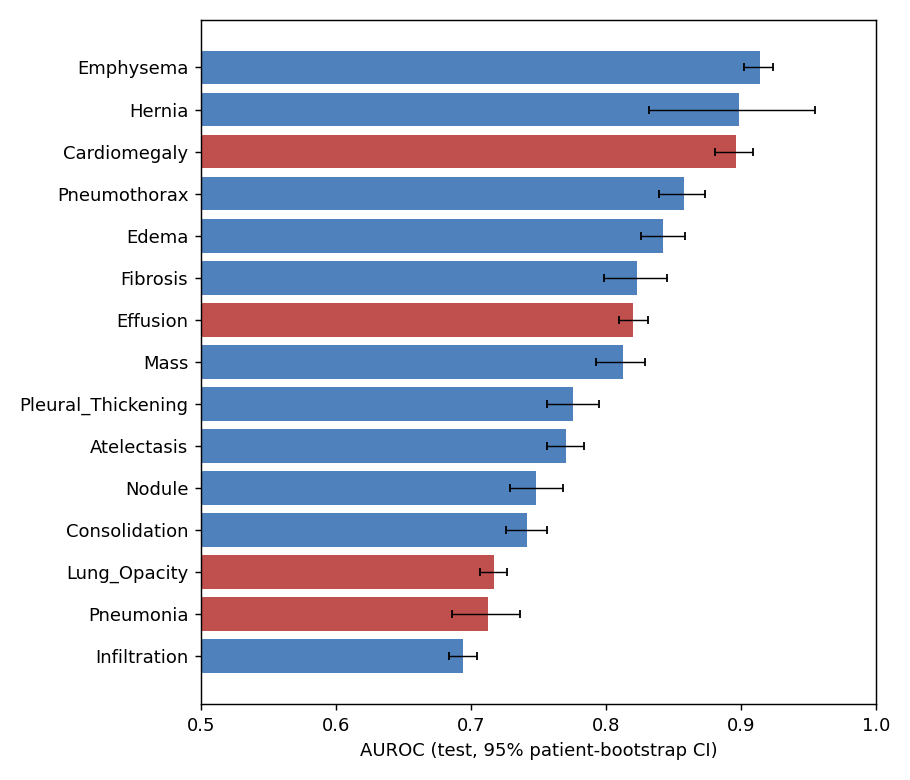

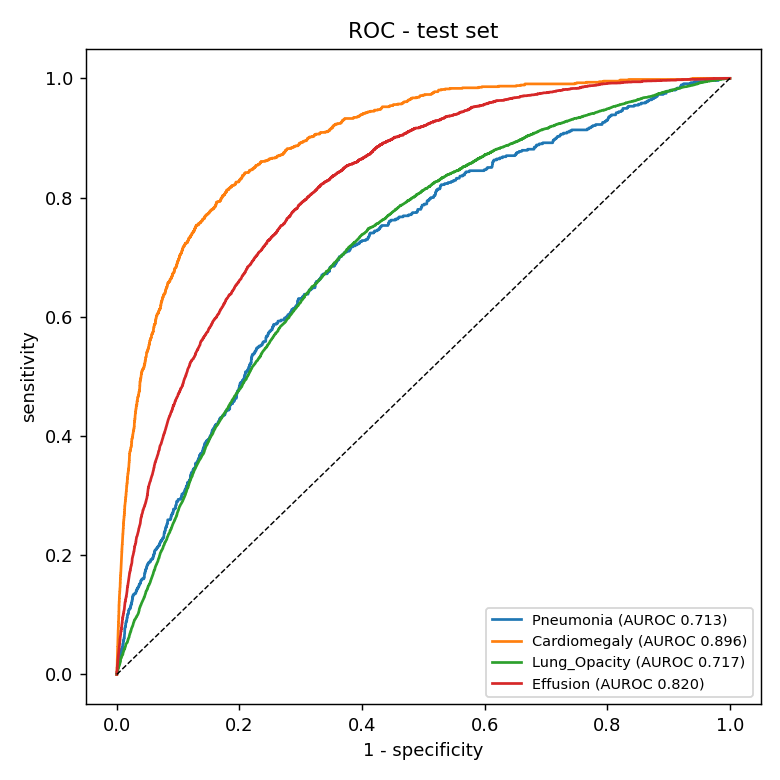

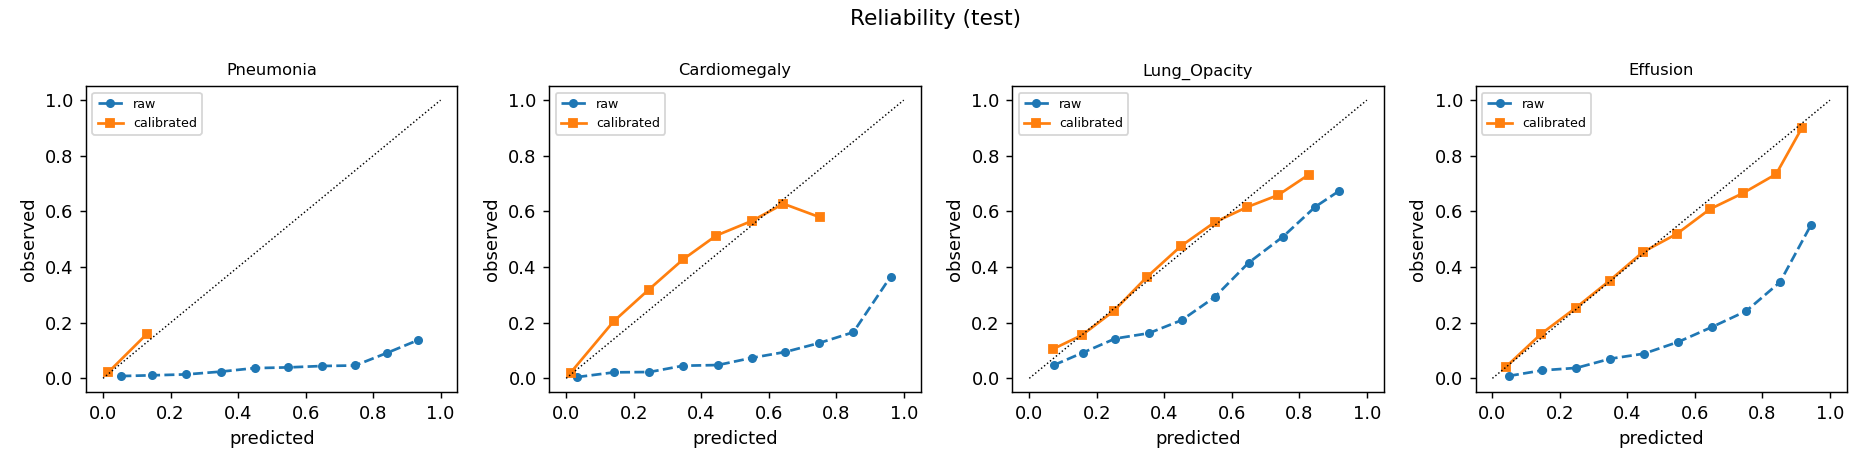

In [6]:
!python scripts/evaluate.py
from IPython.display import Image, Markdown, display
display(Markdown(open('/kaggle/working/eval/eval_report.md').read()))
for f in ['auroc_ci', 'roc_focus', 'reliability_focus']:
    display(Image(f'/kaggle/working/eval/{f}.png'))

## Step 6: Grad-CAM localisation on NIH bounding boxes

I0000 00:00:1795642299.925761     576 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Boxes per split: {'test': 984}
                  n  pointing_acc  centre_baseline  energy_in_box  box_area
label                                                                      
Atelectasis   180.0         0.222            0.078          0.083     0.033
Cardiomegaly  146.0         0.945            0.986          0.538     0.180
Effusion      153.0         0.307            0.033          0.165     0.071
Infiltration  123.0         0.431            0.252          0.177     0.099
Mass           85.0         0.235            0.118          0.125     0.044
Nodule         79.0         0.000            0.000          0.017     0.006
Pneumonia     120.0         0.325            0.158          0.188     0.097
Pneumothorax   98.0         0.122            0.020          0.105     0.054
ALL           984.0         0.355            0.229          0.188     0.078
Outputs -

# Grad-CAM localisation (NIH bounding boxes)

Split: test; boxes evaluated: 984; tolerance: 15 px (1024-px space).

| label        |   n |   pointing_acc |   centre_baseline |   energy_in_box |   box_area |
|:-------------|----:|---------------:|------------------:|----------------:|-----------:|
| Atelectasis  | 180 |          0.222 |             0.078 |           0.083 |      0.033 |
| Cardiomegaly | 146 |          0.945 |             0.986 |           0.538 |      0.18  |
| Effusion     | 153 |          0.307 |             0.033 |           0.165 |      0.071 |
| Infiltration | 123 |          0.431 |             0.252 |           0.177 |      0.099 |
| Mass         |  85 |          0.235 |             0.118 |           0.125 |      0.044 |
| Nodule       |  79 |          0     |             0     |           0.017 |      0.006 |
| Pneumonia    | 120 |          0.325 |             0.158 |           0.188 |      0.097 |
| Pneumothorax |  98 |          0.122 |             0.02  |           0.105 |      0.054 |
| ALL          | 984 |          0.355 |             0.229 |           0.188 |      0.078 |

- **pointing_acc**: hottest CAM pixel inside the box.
- **centre_baseline**: same test for a fixed guess at the image centre. Grad-CAM is only informative where it clearly beats this.
- **energy_in_box vs box_area**: if energy is not well above the box's share of the image, the heatmap is diffuse rather than localised.

Grad-CAM shows where the model looked, not proof that its reasoning is correct.

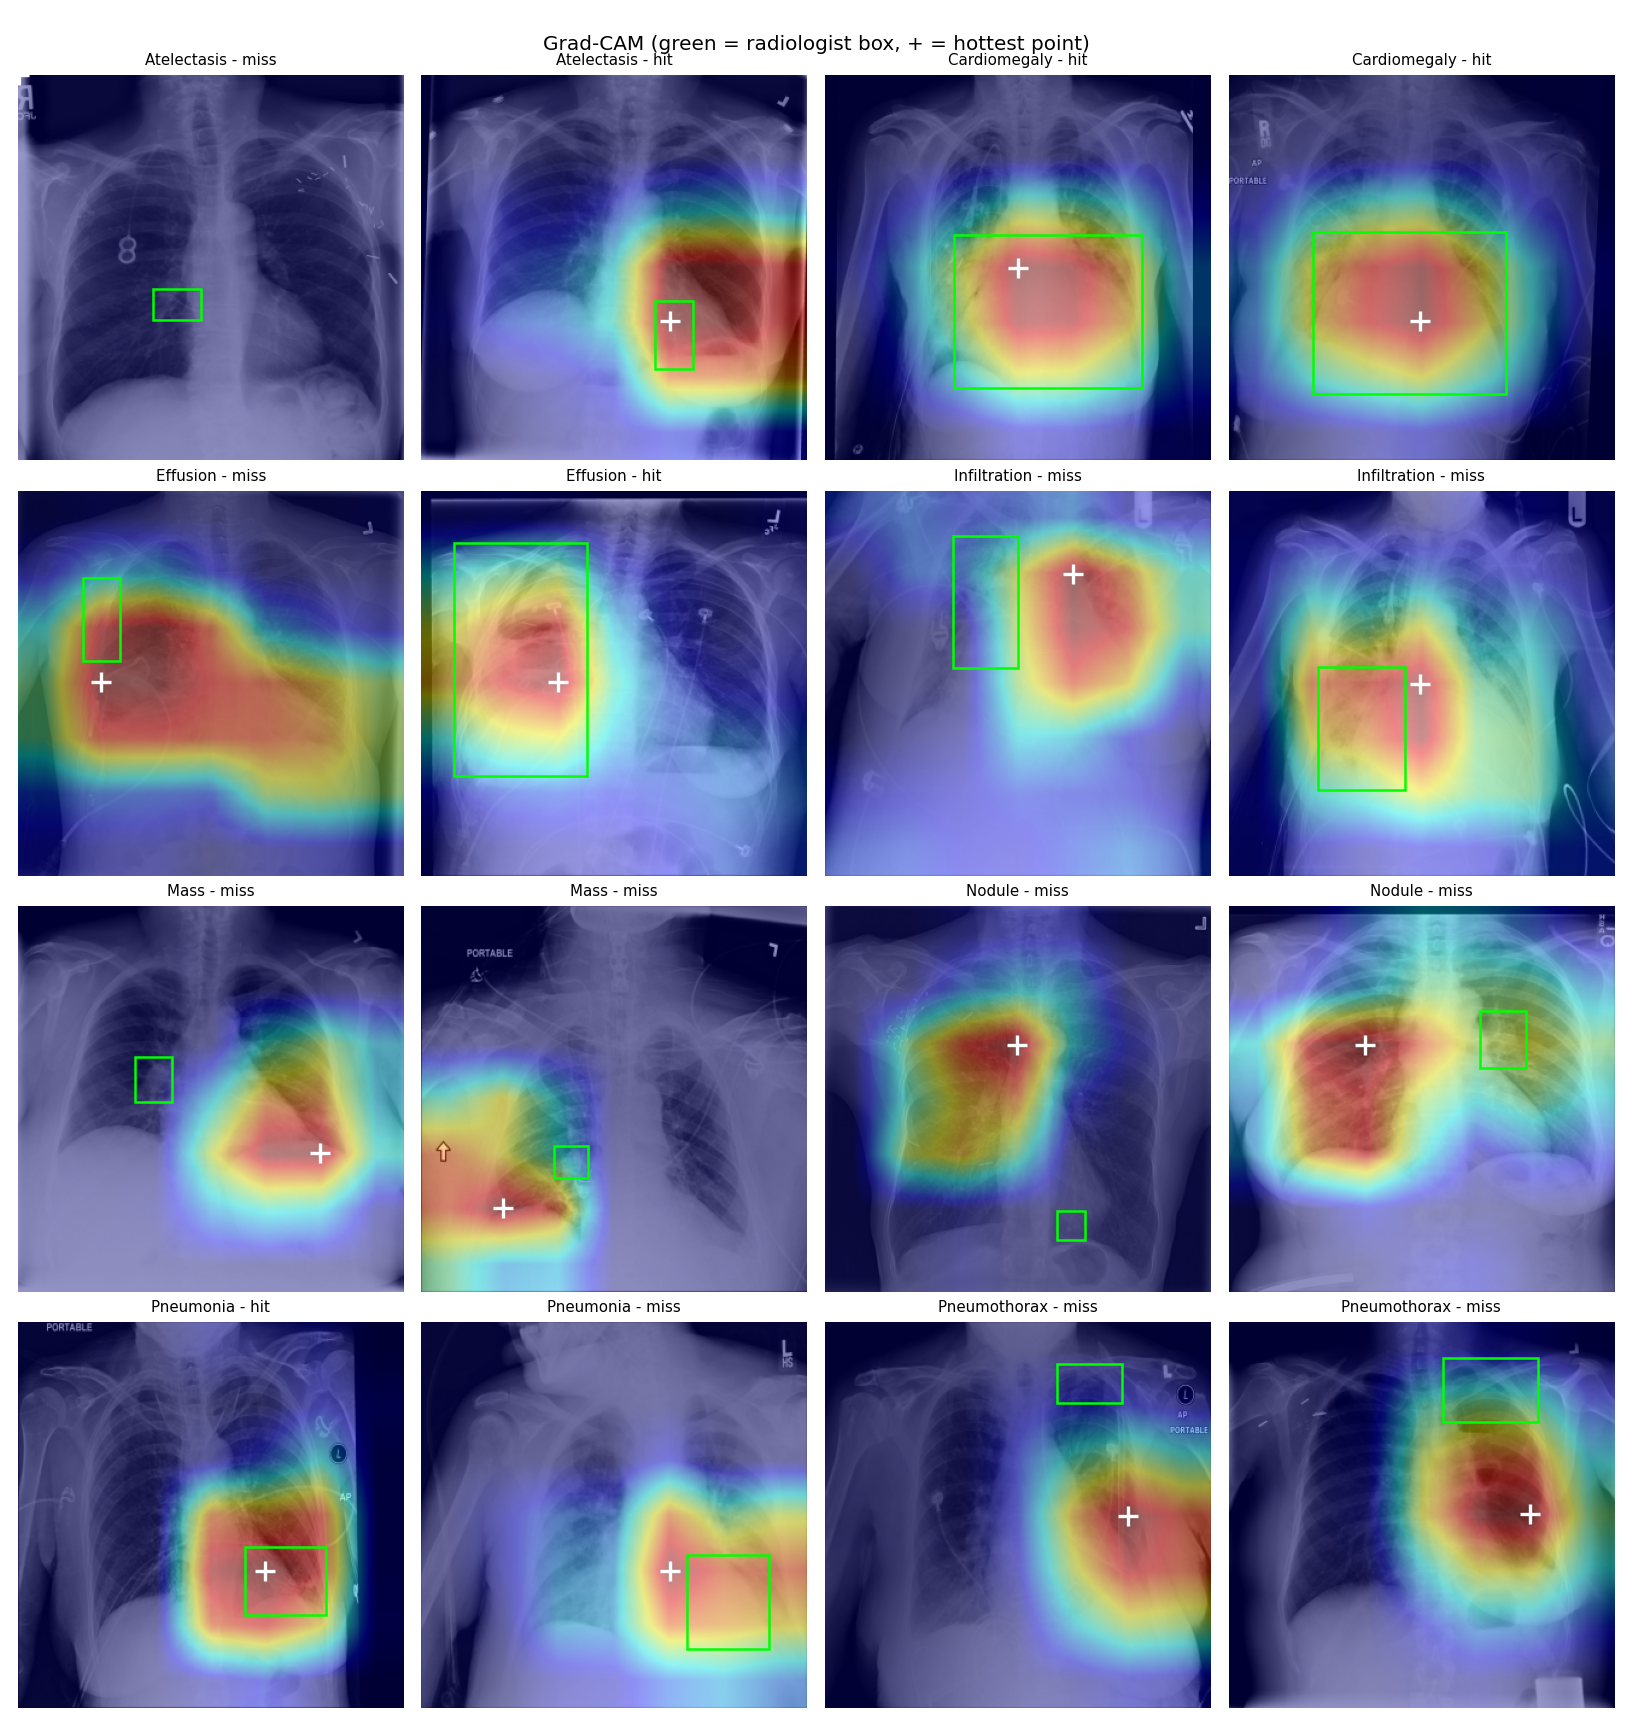

In [7]:
!python scripts/gradcam_eval.py --split test
display(Markdown(open('/kaggle/working/explain/explain_report.md').read()))
display(Image('/kaggle/working/explain/gradcam_gallery.png'))

## Training curve

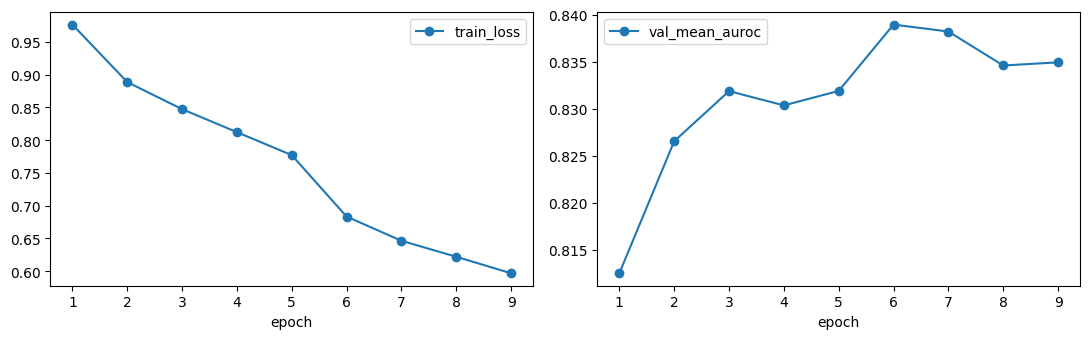

/kaggle/working/checkpoints:
total 27792
drwxr-xr-x 2 root root     4096 Nov 25 20:20 .
drwxr-xr-x 6 root root     4096 Nov 25 21:31 ..
-rw-r--r-- 1 root root 28441850 Nov 25 21:05 best.pt
-rw-r--r-- 1 root root       47 Nov 25 21:28 best_summary.json
-rw-r--r-- 1 root root     3092 Nov 25 21:28 history.csv

/kaggle/working/eval:
total 6056
drwxr-xr-x 2 root root    4096 Nov 25 21:31 .
drwxr-xr-x 6 root root    4096 Nov 25 21:31 ..
-rw-r--r-- 1 root root   45859 Nov 25 21:31 auroc_ci.png
-rw-r--r-- 1 root root    3646 Nov 25 21:30 calibration.json
-rw-r--r-- 1 root root    5162 Nov 25 21:31 eval_report.md
-rw-r--r-- 1 root root     373 Nov 25 21:31 metrics_by_view.csv
-rw-r--r-- 1 root root    1488 Nov 25 21:31 metrics_test.csv
-rw-r--r-- 1 root root   77061 Nov 25 21:31 reliability_focus.png
-rw-r--r-- 1 root root   81825 Nov 25 21:31 roc_focus.png
-rw-r--r-- 1 root root 5959761 Nov 25 21:31 test_predictions.csv


In [8]:
import pandas as pd, matplotlib.pyplot as plt
h = pd.read_csv('/kaggle/working/checkpoints/history.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h.plot(x='epoch', y='train_loss', ax=ax[0], marker='o'); h.plot(x='epoch', y='val_mean_auroc', ax=ax[1], marker='o')
plt.tight_layout(); plt.show()
!ls -la /kaggle/working/checkpoints /kaggle/working/eval

Outputs kept in this version: `checkpoints/best.pt`, `eval/calibration.json` (used by the API and report generator), the evaluation and Grad-CAM reports, and the MLflow history.